# 11주차: 부분 GPU 보관과 선택적 CPU 보관

**질문 1:** 같은 block 회수·실행 모델에서 T-LRU는 block LRU보다 tail 지연을 줄이는가?

**질문 2:** 같은 LRU 회수 순서에서 HotPrefix의 선택적 CPU admission은 전송량 절약을 실제 응답 지연 개선으로 연결하는가?

T-LRU Algorithm 1과 HotPrefix §3.2–3.3의 정책을 세션별 block chain 시뮬레이터에서 평가한다. **HotPrefix 전체 시스템 재현, 선제 승격, CUDA pipeline, 실제 GPU 측정은 아니다.** 세션 간 prefix 공유는 입력에 없으므로 만들지 않는다.

[실험 결과](../docs/week11_experiment.md) · [구현 명세](../docs/week11_policy_implementation.md) · [사전 계획](../docs/week11_policy_plan.md)

[T-LRU 논문](https://arxiv.org/html/2510.15152v1#S4) · [HotPrefix 논문](https://doi.org/10.1145/3749168)

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/data/week11/summary.csv").exists())
DATA = ROOT / "docs/data/week11"
raw = pd.read_csv(DATA / "summary.csv")
comparison = pd.read_csv(DATA / "comparison.csv")
pairs = pd.read_csv(DATA / "paired.csv")
hardware_pairs = pd.read_csv(DATA / "paired_hardware.csv")
manifest = json.loads((DATA / "experiment.json").read_text(encoding="utf-8"))
checks = json.loads((DATA / "validation.json").read_text(encoding="utf-8"))
assert len(raw) == manifest["expected_runs"] == manifest["completed_runs"]
assert raw.groupby(["setting", "condition", "seed"]).trace_sha256.nunique().max() == 1
display(raw.groupby("suite").size().rename("runs").to_frame())
print(checks)

{'runs': 7290, 'suites': {'ablation': 810, 'hardware': 2025, 'main': 4455}, 'unique_input_traces': 405, 'all_paired_inputs_identical': True, 'all_source_hashes_match': True, 'selective_off_exact_matches': 135, 'cpu_free_hardware_exact_matches': 810}


,runs
suite,
ablation,810
hardware,2025
main,4455


## 비교 조건

주 실험은 기존 3개 설정 × 9개 조건 × seed 0–14 × 11개 정책/기준선이다. hardware와 threshold ablation은 seed 0–4를 쓴다. 환경 간 그림은 기본 환경도 같은 seed 0–4로 제한한다.

새 정책의 입장 상한은 모두 100%. CPU를 쓰지 않는 T-LRU의 기준선은 `prefix_lru_evict`, 선택적 CPU 보관의 기준선은 `prefix_lru_offload`다. 기존 `lru_offload`와 새 block 기준선의 차이에는 **회수 단위·CPU 교체·in-flight 처리 차이**가 있으므로 정책 우수성의 근거로 합치지 않는다.

각 run의 P95를 구한 뒤 seed·조건별로 평균낸 값이다. 전체 요청을 합친 P95가 아니다.

In [2]:
variants = ["lru_offload", "prefix_lru_evict", "tlru", "prefix_lru_offload", "hotprefix_admission"]
main = raw[(raw.suite == "main") & raw.variant.isin(variants)].copy()
main["transfer_gib"] = main.transfer_bytes / 2**30
metrics = ["normal_p95_ttft_ms", "resume_p95_ms", "transfer_gib", "recomputed_tokens", "stress_completion_pct"]
display(main.groupby(["setting", "variant"])[metrics].mean().round(3))

normal_p95_ttft_ms  ...  stress_completion_pct
setting variant                                  ...                       
180s_02 hotprefix_admission             292.495  ...                  100.0
        lru_offload                     270.057  ...                  100.0
        prefix_lru_evict                385.223  ...                  100.0
        prefix_lru_offload              270.450  ...                  100.0
        tlru                            342.587  ...                  100.0
180s_03 hotprefix_admission             497.208  ...                  100.0
        lru_offload                     447.518  ...                  100.0
        prefix_lru_evict                759.476  ...                  100.0
        prefix_lru_offload              448.522  ...                  100.0
        tlru                            715.200  ...                  100.0
60s_02  hotprefix_admission             314.126  ...                  100.0
        lru_offload                     308.061  ...                  100.0
        prefix_lru_evict                329.457  ...                  100.0
        prefix_lru_offload              307.967  ...                  100.0
        tlru                            314.755  ...                  100.0

[15 rows x 5 columns]

## T-LRU와 HotPrefix의 paired 효과

아래 차이는 **후보 − 기준선**이다. 지연·전송·재계산은 음수가 감소를 뜻한다. `ALL9`는 먼저 같은 seed 안에서 9조건을 평균내고, seed를 단위로 bootstrap한 95% CI다. threshold를 고른 뒤 같은 seed로 성능을 재확인하는 튜닝은 하지 않았다.

In [3]:
primary = pairs[(pairs.suite == "main") & (pairs.condition == "ALL9") & pairs.candidate.isin(["tlru", "hotprefix_admission"])]
columns = ["setting", "candidate", "baseline", "paired_runs", "identical_requests",
           "normal_p95_ttft_ms_delta", "normal_p95_ttft_ms_ci_low", "normal_p95_ttft_ms_ci_high",
           "resume_p95_ms_delta", "resume_p95_ms_ci_low", "resume_p95_ms_ci_high",
           "transfer_bytes_delta_pct", "recomputed_tokens_delta"]
display(primary[columns].round(3))

,setting,candidate,baseline,paired_runs,identical_requests,normal_p95_ttft_ms_delta,normal_p95_ttft_ms_ci_low,normal_p95_ttft_ms_ci_high,resume_p95_ms_delta,resume_p95_ms_ci_low,resume_p95_ms_ci_high,transfer_bytes_delta_pct,recomputed_tokens_delta
360,180s_02,hotprefix_admission,prefix_lru_offload,135,15,22.045,14.724,30.198,96.083,70.672,120.311,-20.469,15028.844
362,180s_02,tlru,prefix_lru_evict,135,19,-42.637,-53.234,-32.913,-97.077,-123.172,-76.182,NaN,-5690.452
390,180s_03,hotprefix_admission,prefix_lru_offload,135,2,48.686,38.345,60.308,159.574,134.684,182.974,-23.627,46863.333
392,180s_03,tlru,prefix_lru_evict,135,3,-44.277,-56.563,-34.113,-79.028,-103.297,-53.784,NaN,-7584.867
420,60s_02,hotprefix_admission,prefix_lru_offload,135,63,6.160,0.243,15.727,44.807,18.433,75.215,-25.009,2617.104
422,60s_02,tlru,prefix_lru_evict,135,69,-14.702,-26.199,-5.728,-63.225,-99.017,-29.756,NaN,-1246.741


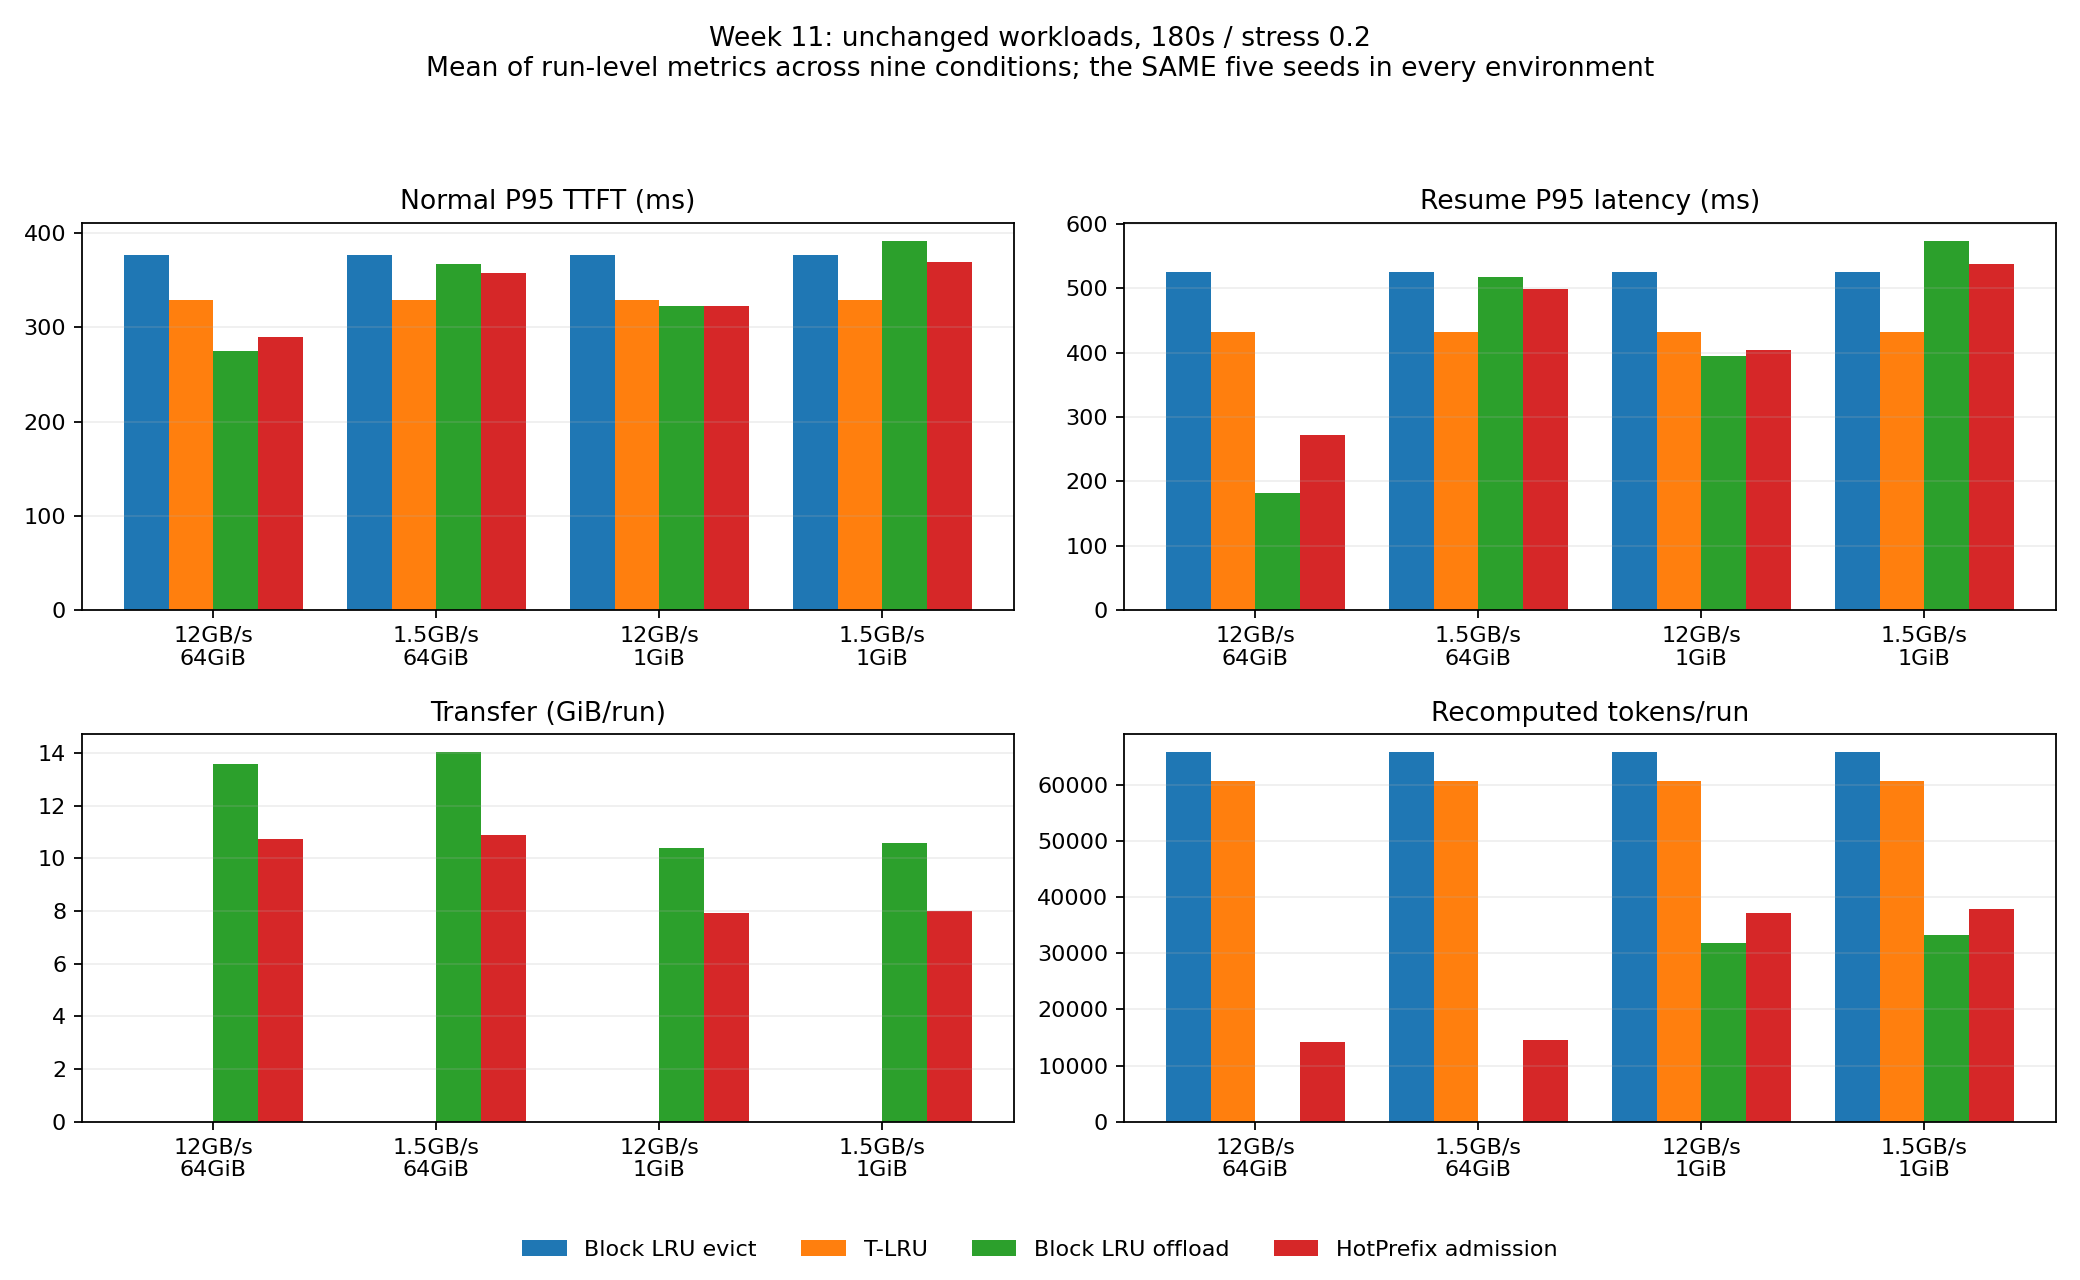

In [4]:
display(Image(filename=str(ROOT / "docs/figures/week11_policy_comparison.png")))

## PCIe·CPU 민감도: 같은 다섯 seed

전송량 감소만으로 성공이라고 판단하지 않는다. 전송 대기 감소가 재계산 증가와 prefill 대기에 의해 상쇄되는지 함께 읽는다. 아래 기본 환경도 seed 0–4만 사용한다.

In [5]:
hw = hardware_pairs[(hardware_pairs.condition == "ALL9") & (hardware_pairs.setting == "180s_02") & hardware_pairs.candidate.isin(["tlru", "hotprefix_admission"])]
display(hw[["environment", "candidate", "baseline", "normal_p95_ttft_ms_delta", "resume_p95_ms_delta",
            "transfer_bytes_delta_pct", "recomputed_tokens_delta", "stress_completion_pct_delta"]].round(3))

,environment,candidate,baseline,normal_p95_ttft_ms_delta,resume_p95_ms_delta,transfer_bytes_delta_pct,recomputed_tokens_delta,stress_completion_pct_delta
0,slow_pcie,hotprefix_admission,prefix_lru_offload,-9.154,-19.374,-22.243,14599.422,0.0
1,slow_pcie,tlru,prefix_lru_evict,-48.037,-92.190,NaN,-5053.133,0.0
20,slow_small,hotprefix_admission,prefix_lru_offload,-22.148,-36.164,-24.680,4665.756,0.0
21,slow_small,tlru,prefix_lru_evict,-48.037,-92.190,NaN,-5053.133,0.0
40,small_cpu,hotprefix_admission,prefix_lru_offload,0.178,9.183,-23.689,5327.444,0.0
41,small_cpu,tlru,prefix_lru_evict,-48.037,-92.190,NaN,-5053.133,0.0
180,default,hotprefix_admission,prefix_lru_offload,14.679,89.560,-20.954,14261.111,0.0
182,default,tlru,prefix_lru_evict,-48.037,-92.190,NaN,-5053.133,0.0


## threshold·GPU 순서 ablation

T-LRU는 100/200/400ms의 prefill 예산을 확인한다. 전체 TTFT 보장은 아니다. HotPrefix의 기본 frequency threshold는 2이고 1/3을 별도로 평가한다. `gpu_hotness`는 논문 §3.3.1의 GPU 순서를 추가한다. `selective_off`는 동일 엔진의 LRU offload와 정확히 같아야 하는 음성 대조군이다.

HotPrefix aging clock은 사용 시 15로 reset하고 100 prefill 완료마다 1 감소시킨다. 15는 논문의 예시값, 100은 논문에 요청 수가 명시되지 않아 사전에 정한 모델 설정이다.

In [6]:
abl = pairs[(pairs.suite == "ablation") & (pairs.setting == "180s_02") & (pairs.condition == "ALL9")]
display(abl[["candidate", "baseline", "paired_runs", "identical_requests", "normal_p95_ttft_ms_delta",
             "resume_p95_ms_delta", "transfer_bytes_delta_pct", "recomputed_tokens_delta"]].round(3))
off = pairs[(pairs.suite == "ablation") & (pairs.candidate == "hotprefix_selective_off") & (pairs.condition != "ALL9")]
assert (off.identical_requests == off.paired_runs).all()
print("Selective-off exact matches:", int(off.identical_requests.sum()))

Selective-off exact matches: 135


,candidate,baseline,paired_runs,identical_requests,normal_p95_ttft_ms_delta,resume_p95_ms_delta,transfer_bytes_delta_pct,recomputed_tokens_delta
0,hotprefix_f1,hotprefix_admission,45,5,-14.679,-89.560,26.501,-14257.200
1,hotprefix_f3,hotprefix_admission,45,5,58.961,188.631,-72.898,37542.244
2,hotprefix_gpu_hotness,hotprefix_admission,45,5,6.233,54.282,-25.951,5800.200
3,hotprefix_selective_off,prefix_lru_offload,45,45,0.000,0.000,0.000,0.000
4,tlru_100ms,tlru,45,6,25.050,34.296,NaN,754.600
5,tlru_400ms,tlru,45,7,22.657,18.762,NaN,2239.622


## 실제 복귀 지연의 분해와 완료율

복귀 지연은 이전 턴 완료 + 도구 대기부터 다음 첫 토큰까지다. 전송 중 복귀로 요청 등록이 늦어진 시간도 포함한다. 아래 성분은 **각 run에서 실제 P95에 해당하는 동일 요청**을 선택한 뒤 집계했다. 서로 다른 성분의 개별 P95를 더하지 않았다.

복귀 측정 cohort는 warm-up 이후 최초 도착한 stress 세션으로 고정한다. `resume_planned_turns`는 거절 때문에 실행되지 못한 후속 턴도 분모에 포함한다.

In [7]:
decomp = main[(main.setting == "180s_02") & (main.condition == "both_4x")]
parts = ["resume_p95_offload_tail_ms", "resume_p95_admission_ms", "resume_p95_restore_ms",
         "resume_p95_prefill_queue_ms", "resume_p95_self_prefill_ms"]
display(decomp.groupby("variant")[parts + ["resume_p95_ms", "resume_planned_turns", "resume_completed_turns", "stress_completion_pct"]].mean().round(3))

,resume_p95_offload_tail_ms,resume_p95_admission_ms,resume_p95_restore_ms,resume_p95_prefill_queue_ms,resume_p95_self_prefill_ms,resume_p95_ms,resume_planned_turns,resume_completed_turns,stress_completion_pct
variant,,,,,,,,,
hotprefix_admission,0.0,25.792,28.372,51.613,52.863,158.633,104.867,104.867,100.0
lru_offload,0.0,28.275,39.177,62.368,18.892,148.706,104.867,104.867,100.0
prefix_lru_evict,0.0,0.000,0.000,130.142,502.169,632.304,104.867,104.867,100.0
prefix_lru_offload,0.0,19.186,28.381,61.005,23.197,131.761,104.867,104.867,100.0
tlru,0.0,0.000,0.000,222.135,395.579,617.710,104.867,104.867,100.0


## 해석의 경계

- 중간 tool call은 반드시 돌아온다. '다시는 안 쓸 KV 검출'을 검증한 것이 아니다.
- 현재 normal 요청은 한 턴이며 완료 후 KV를 해제한다. normal의 재사용 prefix 캐시오염 효과를 만들어내지 않는다.
- 도구 종류, 미래 도구 대기시간, 미래 prompt/남은 턴 수를 새 정책의 입력으로 쓰지 않았다.
- active GPU 예약은 회수하지 못한다. 이 예약과 FIFO prefill이 병목이면 cache 정책의 효과가 제한될 수 있다.
- 비용 누계는 전체 run, `cohort_*` 비용은 warm-up 이후 최초 도착 세션에 귀속한 누계다. 분모가 다른 기존 per-job 비용을 주 판단에 쓰지 않는다.
- 실제 attention/정확도·CUDA 성능은 측정하지 않았다. 시뮬레이터의 결과다.

재실행: `python scripts/run_week11.py --output results/week11_new --workers 4` → `python scripts/report_week11.py results/week11_new`. 디렉터리가 있으면 덮어쓰지 않는다.